In [17]:
import numpy as np
import pandas as pd
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import optax
import unittest
from functools import partial 

import matplotlib.pyplot as plt

# Main functions

In [18]:
@partial(jax.jit, static_argnames=['d'])
def loss_fn(z, inds, Sigma_tilde_vec, d):
    """
    z [jnp.array]: vector supporting precision matrix estimate K(z)
    inds [np.array]: list of the lower triangular nonzero element indices in Sigma_tilde
    Sigma_tilde_vec [np.array]: vector of Sigma_tilde indexed at inds
    d [int]: static argument, number of attributes 
    """

    # reconstruct K_z
    K_z = get_K(z, inds, d)

    # get loss terms
    log_det_term = logdet_psd(K_z)
    trace_term = 2*jnp.dot(z, Sigma_tilde_vec) 
    
    return -log_det_term + trace_term


def get_K(z, inds, d):
    """
    z [jnp.array]: vector supporting precision matrix estimate K(z)
    inds [np.array]: list of the lower triangular nonzero element indices in Sigma_tilde
    d: dimension of Sigma_tilde
    """

    rows = inds[:,0]
    cols = inds[:,1]
    
    K = jnp.zeros((d, d))
    
    # Write lower triangle
    K = K.at[rows, cols].add(z)
    #jax.debug.print("K: {}", K)
    # Write upper triangle (diagonal elements are counted twice, see initialize_z)
    K = K.at[cols, rows].add(z)
    #jax.debug.print("K: {}", K)
    
    return K
    

def initialize_z(Sigma_tilde, inds):
    """
        Sigma_tilde [np.array]: matrix of observed (privatized) covariance entries
        inds [np.array]: vector of indices of nonzero covariance entries
    """

    d = Sigma_tilde.shape[0]

    z_init = []
    
    for (i,j) in inds:
        if i == j:
            z_init.append( max(0.01, 1./Sigma_tilde[i,j]) / 2 ) # diagonal is halved to match K construction in get_K
        else:
            z_init.append(0)
        
    return jnp.array(z_init)

    
def optimize_lbfgs(Sigma_tilde_vec, z, inds, d, max_iters=100, verbose=True):
    """
        Sigma_tilde [np.array]: matrix of observed (privatized) covariance entries
        z [jnp.array]: vector supporting K(z)
        inds [np.array]: vector of indices of nonzero covariance entries
    """
    # get d from inds as the len of (i,i) elements 
    
    # Linesearch, comment/uncomment the desired one
    # linesearch = optax.scale_by_backtracking_linesearch(max_backtracking_steps=15)
    linesearch = optax.scale_by_zoom_linesearch(max_linesearch_steps=15)
    
    # Optimizer
    opt = optax.chain(
        optax.lbfgs(),
        # Compare with or without linesearch by commenting this line
        linesearch,
    )
    
    # Initialize
    state = opt.init(z)

    loss_fn_wrapper = partial(loss_fn, inds=inds, Sigma_tilde_vec=Sigma_tilde_vec, d=d)

    g_vals = []
    obj_vals = []
    
    # Run optimization
    for i in range(max_iters):
        v, g = jax.value_and_grad(loss_fn_wrapper)(z)
        obj_vals.append(v)
        
        updates, state = opt.update(g, state, z, value=v, grad=g, value_fn=loss_fn_wrapper)
        z = optax.apply_updates(z, updates)
        #z = jnp.add(z, updates)

        if verbose:
            print(f'iter: {i}, value:{v:.7e}')
            print(f"grad sum: {jnp.sum(jnp.abs(g))}")
            print(f"grad: {g}")
            print("z", z)
        
            # K_z = get_K(z, inds, d)
            # # if not is_positive_definite(K_z):
            # #     print("NOT PD")
            # #     #z = binary_search_pd_point(z, g)
            # log_det_1 = logdet_psd(K_z)
            # s, log_det_2 = jnp.linalg.slogdet(K_z)
            # print("compare log det", log_det_1, log_det_2)
            # print("\n")

        g_vals.append(jnp.sum(jnp.abs(g)))
        
    plt.plot(g_vals)
    plt.show()

    plt.plot(obj_vals)
    plt.show()
    
    return z

# Helpers

In [19]:
def get_observed_Sigma_entries(Sigma):

    d = Sigma.shape[0]

    diag_inds = [(i,i) for i in range(d)]   # assumed it's always observed
    tril_inds = get_strict_lower_triangle_nonzero(Sigma)
    triu_inds = [(j,i) for (i, j) in tril_inds]

    all_observed_inds = diag_inds + tril_inds + triu_inds

    print(np.array(all_observed_inds))
    
    return np.array(all_observed_inds)

def compute_d(inds):
    mask = (inds[:, 0] == inds[:, 1])
    d = np.sum(mask)
    return d

def is_positive_definite(M):
    return jnp.all(jnp.linalg.eigvalsh(M) > 0)

def get_strict_lower_triangle_nonzero(M):
    # lower triangle indices excluding the diagonal
    lower_triangle_indices = np.tril_indices(M.shape[0], k=-1)
    
    # nonzero elements in the lower triangle
    nonzero_mask = M[lower_triangle_indices] != 0
    filtered_indices = (lower_triangle_indices[0][nonzero_mask], lower_triangle_indices[1][nonzero_mask])
    
    # zip indices together into tuples
    indices_tuples = list(zip(filtered_indices[0].tolist(), filtered_indices[1].tolist()))
    
    return indices_tuples


@jax.jit
def logdet_psd(A):
    # Compute the Cholesky decomposition
    L = jnp.linalg.cholesky(A)

    # Check if any entry of the Cholesky factor is NaN
    is_nan = jnp.any(jnp.isnan(L))

    def nan_case(_):
        return -jnp.inf

    def valid_case(L):
        diag_L = jnp.diag(L)
        log_det = 2 * jnp.sum(jnp.log(diag_L))
        return log_det

    # Use jax.cond to choose between the cases
    return jax.lax.cond(is_nan, nan_case, valid_case, L)

def generate_multivariate_normal_data(n, d):
    mean = np.zeros(d)
    
    # Define a random positive definite covariance matrix (4x4)
    A = np.random.rand(n, d)
    covariance_matrix = np.dot(A.transpose(), A)
    
    # Generate the multivariate normal dataset
    dataset = np.random.multivariate_normal(mean, covariance_matrix, n)
    
    return dataset, covariance_matrix


def get_Sigma_tilde_d4(cov, off_diag_positions):
    M = np.zeros_like(cov)
    
    # copy diagonal
    np.fill_diagonal(M, np.diag(cov))
    
    # check if (i, j) is a valid lower triangular element (i > j)
    for (i,j) in off_diag_positions:
        M[i, j] = cov[i, j]
        M[j, i] = cov[j, i]
    
    return M

def get_Sigma_tilde_d15(cov, off_diagonal_percentage=0.15):
    # by ChatGPT, review
    d = cov.shape[0]
    assert d == 15, "The function is designed for 15x15 matrices only."
    
    M = np.zeros_like(cov)
    
    # Copy diagonal
    np.fill_diagonal(M, np.diag(cov))
    
    # Number of off-diagonal entries to fill
    num_off_diagonal = int(off_diagonal_percentage * (d * (d - 1)) / 2)
    
    # Generate all possible off-diagonal indices
    off_diagonal_indices = [(i, j) for i in range(d) for j in range(i+1, d)]
    
    # Randomly select indices to fill
    selected_indices = np.random.choice(len(off_diagonal_indices), num_off_diagonal, replace=False)
    
    for idx in selected_indices:
        i, j = off_diagonal_indices[idx]
        M[i, j] = cov[i, j]
        M[j, i] = cov[j, i]
    
    return M

def is_positive_definite(K):
    return jnp.all(jnp.linalg.eigvalsh(K) > 0)

def generate_chain_case():

    prec = np.array([[1, -0.5,  0,    0],
                 [-0.5, 1, -0.5,  0],
                 [0, -0.5,  1, -0.5],
                 [0,  0, -0.5,  1]])
    
    # Invert the precision matrix to get the covariance matrix
    cov = np.linalg.inv(prec)

    mask = prec != 0
    masked_cov = np.where(mask, cov, 0)
    
    return cov, prec, masked_cov

# Tests

In [20]:
class TestAuxiliaryFunctions(unittest.TestCase):
    def test_get_K(self):
        d = 3
        z = np.array([0.5, 1., 1.5, 4., 5.])
        # Updated indices to be within bounds for a 3x3 matrix
        inds = np.array([(0, 0), (1, 1), (2, 2), (1, 0), (2, 0)])
        
        K_result = get_K(z, inds, d)
        
        # Updated expected result matrix based on the new indices
        K_true = np.array([[1., 4., 5.],
                           [4., 2., 0.],
                           [5., 0., 3.]])

        print(K_true)
        print(K_result)
        
        assert np.allclose(K_result, K_true, atol=1e-10), "test_get_K failed"

    def test_initialize_z(self):
        Sigma_tilde = np.array([[1000., 0., 4.],
                               [0., 2., 0.],
                               [4., 0., 3.]])
        inds = np.array([(0, 0), (1, 1), (2, 2), (2, 0)])
        d = Sigma_tilde.shape[0]
        
        z_true = np.array([0.01 / 2., 
                           1/2 / 2., 
                           1/3 / 2., 
                           0.])  
        
        z_init = initialize_z(Sigma_tilde, inds)

        for i in range(d):
            self.assertTrue(np.allclose(z_true, z_init, atol=1e-10)), "test_initialize_z failed"

    def test_trace_terms(self):
        np.random.seed(1)
        d = 4
        n = 100
        x = np.random.randn(n,d)
        
        Sigma = x.T.dot(x)
        
        # observed indices
        inds = np.array([[0, 0], [1, 1], [2,2], [3, 3], [3, 0]])
        z = np.array([10/2., 20/2., 30/2., 40/2., 50]) # diagonal entries are halved
        
        rows = inds[:,0]
        cols = inds[:,1]
        
        Sigma_tilde = np.zeros((d,d))
        Sigma_tilde[rows, cols] = Sigma[rows, cols]
        Sigma_tilde[cols, rows] = Sigma[cols, rows]
        
        Sigma_tilde_vec = Sigma_tilde[rows, cols]
        
        print(f"Sigma:\n{Sigma}\n")
        print(f"Sigma_tilde:\n{Sigma_tilde}\n")
        print(f"Sigma_tilde_vec:\n{Sigma_tilde_vec}\n")
        
        K = get_K(z, inds, d)
        
        print(f"z: {z}")
        print(f"K: {K}")
        
        trace_term_1 = np.trace(K.dot(Sigma_tilde))
        print(f"trace_term_1, {trace_term_1}")
        
        trace_term_2 = 2*np.dot(Sigma_tilde_vec, z)
        print(f"trace_term_2, {trace_term_2}")

        assert np.allclose(trace_term_1, trace_term_2, atol=1e-10), "test_trace_terms failed"
            
unittest.main(argv=[''], verbosity=2, exit=False)

test_get_K (__main__.TestAuxiliaryFunctions) ... ok
test_initialize_z (__main__.TestAuxiliaryFunctions) ... ok
test_trace_terms (__main__.TestAuxiliaryFunctions) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.032s

OK


[[1. 4. 5.]
 [4. 2. 0.]
 [5. 0. 3.]]
[[1. 4. 5.]
 [4. 2. 0.]
 [5. 0. 3.]]
Sigma:
[[102.50631974 -27.85384821   5.40372564  -7.11780264]
 [-27.85384821  92.12516717   3.94075161  -4.00545589]
 [  5.40372564   3.94075161  88.87655612   4.90562789]
 [ -7.11780264  -4.00545589   4.90562789  98.74319209]]

Sigma_tilde:
[[102.50631974   0.           0.          -7.11780264]
 [  0.          92.12516717   0.           0.        ]
 [  0.           0.          88.87655612   0.        ]
 [ -7.11780264   0.           0.          98.74319209]]

Sigma_tilde_vec:
[102.50631974  92.12516717  88.87655612  98.74319209  -7.11780264]

z: [ 5. 10. 15. 20. 50.]
K: [[10.  0.  0. 50.]
 [ 0. 20.  0.  0.]
 [ 0.  0. 30.  0.]
 [50.  0.  0. 40.]]
trace_term_1, 8771.810644126272
trace_term_2, 8771.810644126272


# Drivers

In [25]:
def run_adult_d4(off_diag_positions):
    adult_path = "/Users/ceciliaferrando/Documents/UMASS/RESEARCH/DPsynthesisML/hd-datasets-master/clean/adult.csv"
    adult_data_d4 = pd.read_csv(adult_path)[["age", "workclass", "fnlwgt", "education"]]
    
    Sigma_true = adult_data_d4.cov().to_numpy()
    Prec_true = np.linalg.inv(Sigma_true)
    
    Sigma_tilde = get_Sigma_tilde_d4(Sigma_true, off_diag_positions)
    Prec_tilde = np.linalg.inv(Sigma_tilde)
    inds = get_observed_Sigma_entries(Sigma_tilde)
    d = compute_d(inds)
    rows, cols = inds[:,0], inds[:,1]
    Sigma_tilde_vec = Sigma_tilde[rows, cols]
    
    z_init = initialize_z(Sigma_tilde, inds)
    K_z_init = get_K(z_init, inds, d)
    
    z_opt = optimize_lbfgs(Sigma_tilde_vec, z_init, inds, d, max_iters=10)
    K_z_opt = get_K(z_opt, inds, d)

    Sigma_opt = np.linalg.inv(K_z_opt)
    
    mse = np.sum(np.abs(np.subtract(Sigma_true, Sigma_opt)))

    print("MSE", mse)

    print("Sigma_true", Sigma_true)
    print("Prec_true", Prec_true)
    print("\n")
    print("Sigma_tilde", Sigma_tilde)
    print("Prec_tilde", Prec_tilde)
    print("\n")
    print("Sigma_opt", np.linalg.inv(K_z_opt))
    print("Prec_opt", K_z_opt)
    
    return mse

def adult_d4_comparison(off_diag_positions):
    results = {}
    for lvl in range(len(off_diag_positions)+1):
        mse = run_adult_d4(off_diag_positions[:lvl])
        results[lvl] = mse
    return results

def run_adult():
    adult_path = "/Users/ceciliaferrando/Documents/UMASS/RESEARCH/DPsynthesisML/hd-datasets-master/clean/adult.csv"
    adult_data = pd.read_csv(adult_path)
    n, d = adult_data.shape
    Sigma_true = adult_data.cov().to_numpy()
    Prec_true = np.linalg.inv(Sigma_true)
    Sigma_tilde = get_Sigma_tilde_d15(Sigma_true, off_diagonal_percentage=0.15)
    Prec_tilde = np.linalg.inv(Sigma_tilde)
    inds = get_observed_Sigma_entries(Sigma_tilde)

    d = compute_d(inds)
    rows, cols = inds[:,0], inds[:,1]
    Sigma_tilde_vec = Sigma_tilde[rows, cols]
    
    z_init = initialize_z(Sigma_tilde, inds)
    K_z_init = get_K(z_init, inds, d)
    
    z_opt = optimize_lbfgs(Sigma_tilde_vec, z_init, inds, d, max_iters=50)
    K_z_opt = get_K(z_opt, inds, d)

    Sigma_opt = np.linalg.inv(K_z_opt)
    
    mse = np.sum(np.abs(np.subtract(Sigma_true, Sigma_opt)))

    print("MSE", mse)

    print("Sigma_true", Sigma_true)
    print("Prec_true", Prec_true)
    print("\n")
    print("Sigma_tilde", Sigma_tilde)
    print("Prec_tilde", Prec_tilde)
    print("\n")
    print("Sigma_opt", np.linalg.inv(K_z_opt))
    print("Prec_opt", K_z_opt)
    
    return mse



def run_chain_case():
    Sigma_true, Prec_true, Sigma_tilde = generate_chain_case()
    Prec_tilde = np.linalg.inv(Sigma_tilde)
    d = Sigma_tilde.shape[0]
    
    inds = get_observed_Sigma_entries(Sigma_tilde)
    
    print(f"Sigma_tilde, {Sigma_tilde}")
    
    z_init = initialize_z(Sigma_tilde, inds)
    K_z_init = get_K(z_init,  inds, d)
    
    z_opt = optimize_lbfgs(Sigma_tilde, z_init, inds, max_iters=30)

    K_z_opt = get_K(z_opt, inds, 4)
    
    print("Sigma_true", Sigma_true)
    print("Sigma_tilde", Sigma_tilde)
    print("Sigma_opt", np.linalg.inv(K_z_opt))
    print("\n")
    print("Prec_true", Prec_true)
    print("Prec_tilde", Prec_tilde)
    print("Prec_opt", K_z_opt)
    return z_opt

# Adult 4x4 error vs offdiagonal entries

In [23]:
adult_d4_comparison([(1,0), (2,0), (2,1), (3,0), (3, 1), (3, 2)])

[[0 0]
 [1 1]
 [2 2]
 [3 3]]
iter: 0, value:1.3227171e+01
grad sum: 1.9539925233402755e-14
grad: [-7.10542736e-15  0.00000000e+00 -1.77635684e-15  1.06581410e-14]
z [0.01883336 0.10258236 0.09550577 0.03330737]



KeyboardInterrupt



# Adult

[[ 0  0]
 [ 1  1]
 [ 2  2]
 [ 3  3]
 [ 4  4]
 [ 5  5]
 [ 6  6]
 [ 7  7]
 [ 8  8]
 [ 9  9]
 [10 10]
 [11 11]
 [12 12]
 [13 13]
 [14 14]
 [ 3  1]
 [ 6  5]
 [ 7  1]
 [ 9  2]
 [10  3]
 [10  8]
 [11  7]
 [11  9]
 [11 10]
 [12  1]
 [12  6]
 [13  1]
 [13  3]
 [13  9]
 [14  7]
 [ 1  3]
 [ 5  6]
 [ 1  7]
 [ 2  9]
 [ 3 10]
 [ 8 10]
 [ 7 11]
 [ 9 11]
 [10 11]
 [ 1 12]
 [ 6 12]
 [ 1 13]
 [ 3 13]
 [ 9 13]
 [ 7 14]]
iter: 0, value:3.6938457e+01
grad sum: 25.385734474456644
grad: [ 2.13162821e-14  1.77635684e-15  3.55271368e-15  3.55271368e-15
  5.32907052e-15  0.00000000e+00 -3.55271368e-15  8.88178420e-16
 -8.88178420e-16 -1.11022302e-16  3.55271368e-15  1.77635684e-15
  0.00000000e+00  0.00000000e+00 -1.11022302e-16  4.02357260e-01
  5.21836047e-01 -1.77179874e-01  5.78393929e-02  4.99534380e-01
 -1.06845464e-01 -1.69137737e-01  1.07584587e-01 -3.24483292e-01
 -2.05103933e+00 -2.10034515e+00 -1.10814914e+00 -4.79826609e+00
  8.51844037e-02 -1.83085098e-01  4.02357260e-01  5.21836047e-01
 -1.771798

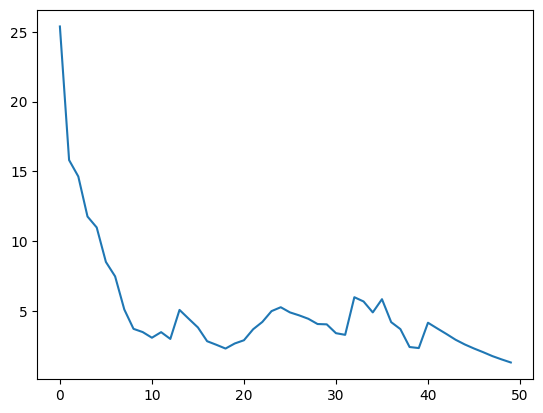

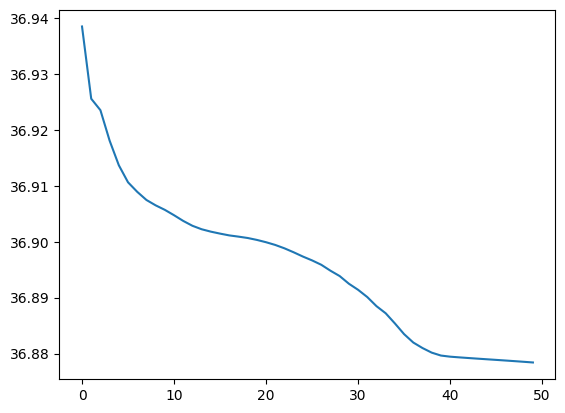

MSE 77.31963915763075
Sigma_true [[ 2.65486314e+01  1.12558197e+00 -9.22363910e-01 -2.94606949e-01
   4.19322938e-01 -1.33256091e+00  6.63984134e-01  8.12983385e-01
  -1.76772016e-01  2.13452425e-01  8.55234974e-01  7.30598679e-01
   1.48889862e+00 -8.44349487e-01  5.04702921e-01]
 [ 1.12558197e+00  4.87413218e+00 -1.08345319e-01  2.01178630e-01
   2.87266037e-01  8.13887018e-02  4.15097129e+00 -8.85899371e-02
   1.03851217e-01 -5.56511224e-02 -2.39842511e-02  1.54525415e-02
  -1.02551966e+00 -5.54074570e-01 -8.47154464e-03]
 [-9.22363910e-01 -1.08345319e-01  5.23528579e+00 -1.99091992e-01
  -2.30920697e-01  6.76691231e-02 -3.58955702e-04  3.84921372e-02
   2.91511141e-01  2.89196964e-02 -1.75814372e-02 -2.84153292e-02
  -1.24947412e-01  1.21550142e+00 -6.78373232e-03]
 [-2.94606949e-01  2.01178630e-01 -1.99091992e-01  1.50116916e+01
   3.58272695e+00 -1.47761344e-01 -7.98710468e-02 -6.61787769e-02
  -1.32112502e-01 -4.93214012e-02  2.49767190e-01  1.70815448e-01
   8.88022310e-01 -2.3

np.float64(77.31963915763075)

In [26]:
run_adult()